# Assignment Problems: Day 10

The following problems require access to the file named ‘Dataset_Day10.csv’, provided with this assignment. (Use Random State = 50)

This is the same assignment data as Day 9.

The datasets include data from 768 women with several medical predictor variables and one target variable(‘Outcome’). The classification goal is to predict whether or not the patients in the dataset have diabetes or not.

For columns: Glucose, BloodPressure, BMI, DiabetesPedigreeFunction

If the column value is 0, then they should be considered as missing data.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn import tree
from math import log, sqrt
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, log_loss, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

* Firstly, replace all Missing values with relevant figures.
* Then remove all existing outliers and get the final data for classification.

In [2]:
data = pd.read_csv("Dataset_Day7.csv")

# Missing data treatment
print('Before Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    data[col][data[col]==0] = data[col].median()
print('\nAfter Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))

outlier = pd.DataFrame(columns = ["Pregnancies","Glucose","BloodPressure","BMI","Age"])
temp = data.drop('Outcome',axis=1)
for col in ["Pregnancies","Glucose","BloodPressure","BMI","Age"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    outlier[col] = temp[col][(temp[col]<=LowerBound)|(temp[col]>=UpperBound)]

OutlierFreeData = data.drop(outlier.index,axis=0)
print("\nno. of Outlier",len(outlier), "\n% of Outlier = ", str(len(outlier)/len(data)*100))

Before Missing Data Treatment
Glucose  =  5
BloodPressure  =  35
BMI  =  11
DiabetesPedigreeFunction  =  0

After Missing Data Treatment
Glucose  =  0
BloodPressure  =  0
BMI  =  0
DiabetesPedigreeFunction  =  0

no. of Outlier 4 
% of Outlier =  0.5208333333333333


C:\Users\nikhi\AppData\Local\Temp\ipykernel_1716\3315839205.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col][data[col]==0] = data[col].median()


* Split the data into 80% training and 20% testing data. Then, use a Decision Tree classifier algorithm with target variable as ‘Outcome’.
* Print the default model performance metrics: Accuracy, Precision, Recall, F1Score

Model Performance metrics are as below :-

Accuracy is  0.803921568627451
Precision is  0.7090909090909091
Recall is  0.7358490566037735
F1-Score is  0.7222222222222221
[[84 16]
 [14 39]]


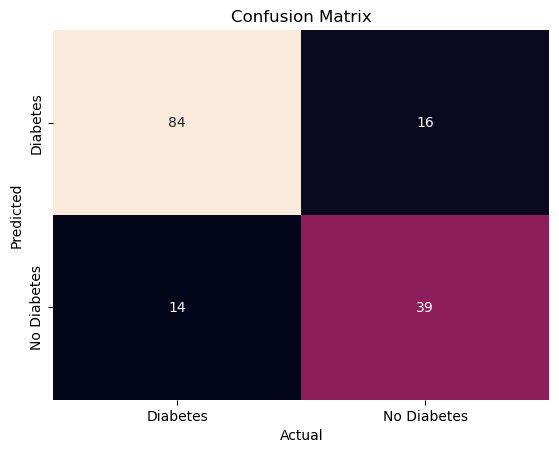

|--- feature_1 <= 127.50
|   |--- feature_5 <= 28.50
|   |   |--- feature_3 <= 30.95
|   |   |   |--- feature_4 <= 0.67
|   |   |   |   |--- class: 0
|   |   |   |--- feature_4 >  0.67
|   |   |   |   |--- feature_3 <= 24.05
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- feature_3 >  24.05
|   |   |   |   |   |--- class: 0
|   |   |--- feature_3 >  30.95
|   |   |   |--- feature_4 <= 0.90
|   |   |   |   |--- feature_2 <= 94.00
|   |   |   |   |   |--- feature_3 <= 31.10
|   |   |   |   |   |   |--- feature_2 <= 65.00
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |--- feature_2 >  65.00
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- feature_3 >  31.10
|   |   |   |   |   |   |--- feature_1 <= 89.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- feature_1 >  89.50
|   |   |   |   |   |   |   |--- feature_4 <= 0.14
|   |   |   |   |   |   |   |   |--- feature_1 <= 118.00
|   |   |   |   |   |   |   |   |   |--- class

In [3]:
# Spliting of data 7:3
X = OutlierFreeData.drop("Outcome",axis=1)
y = OutlierFreeData["Outcome"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20, random_state=4)

model = DecisionTreeClassifier(random_state = 64)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Model Performance metrics are as below :-\n")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()
print(tree.export_text(model))

* Plot a Precision & Recall vs max_leaf_nodes (consider a range of numbers) curve (both Prec and Rec on the same graph). Find the kernel type for which F1-score is the highest.
* Plot a Precision & Recall vs max_depth (consider a range of numbers) curve (both Prec and Rec on the same graph). Find the kernel type for which F1-score is the highest.

In [4]:
criterion = ['gini','entropy', 'log_loss']

df = pd.DataFrame(columns=['Criterion','Max Tree Depth','Max Leaf Nodes','precision','recall','f1-Score'])
for c in criterion:
    for md in range(1,25):
        for mln in range(2,25):
                model = DecisionTreeClassifier(criterion = c, max_depth = md, max_leaf_nodes = mln, random_state = 64)
                model = model.fit(X_train,y_train)
                y_pred = model.predict(X_test)
                df = pd.concat([pd.DataFrame([[c, md, mln, precision_score(y_test,y_pred), recall_score(y_test,y_pred), f1_score(y_test,y_pred)]], columns=df.columns), df], ignore_index=True)

display(df[(df['f1-Score'] == max(df['f1-Score']))])

,Criterion,Max Tree Depth,Max Leaf Nodes,precision,recall,f1-Score
1107,gini,24,21,0.759259,0.773585,0.766355
1108,gini,24,20,0.759259,0.773585,0.766355
1130,gini,23,21,0.759259,0.773585,0.766355
1131,gini,23,20,0.759259,0.773585,0.766355
1153,gini,22,21,0.759259,0.773585,0.766355
1154,gini,22,20,0.759259,0.773585,0.766355
1176,gini,21,21,0.759259,0.773585,0.766355
1177,gini,21,20,0.759259,0.773585,0.766355
1199,gini,20,21,0.759259,0.773585,0.766355
1200,gini,20,20,0.759259,0.773585,0.766355


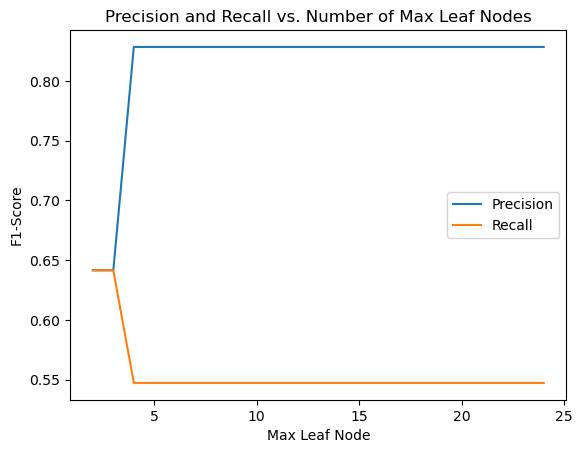

In [10]:
# Plotting precision and recall scores against Max Leaf Nodes
y = df[df['Max Tree Depth']==2]
x = y[y['Criterion']=='gini']
plt.plot(x["Max Leaf Nodes"], x["precision"], label='Precision')
plt.plot(x["Max Leaf Nodes"], x["recall"], label='Recall')
plt.xlabel('Max Leaf Node')
plt.ylabel('F1-Score')
plt.title('Precision and Recall vs. Number of Max Leaf Nodes')
plt.legend()
plt.show()

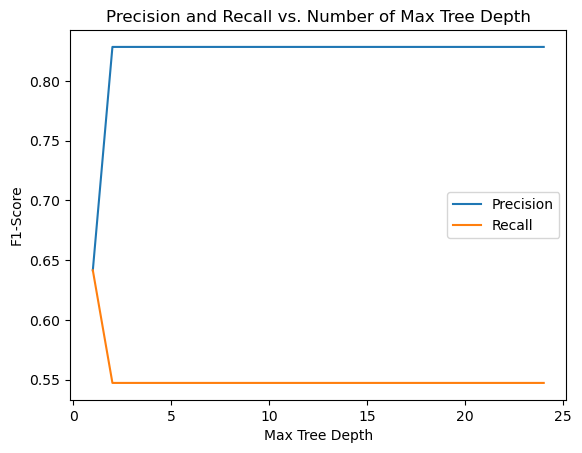

In [12]:
# Plotting precision and recall scores against Max Tree Depth
y = df[df['Max Leaf Nodes']==4]
x = y[y['Criterion']=='gini']
plt.plot(x["Max Tree Depth"], x["precision"], label='Precision')
plt.plot(x["Max Tree Depth"], x["recall"], label='Recall')
plt.xlabel('Max Tree Depth')
plt.ylabel('F1-Score')
plt.title('Precision and Recall vs. Number of Max Tree Depth')
plt.legend()
plt.show()

In [7]:
model = DecisionTreeClassifier(criterion = 'gini', max_depth = 9, max_leaf_nodes = 20, random_state = 64)
model = model.fit(X_train,y_train)
y_pred = model.predict(X_test)
print("Model Performance metrics are as below :-")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

Model Performance metrics are as below :-
Accuracy is  0.8366013071895425
Precision is  0.7592592592592593
Recall is  0.7735849056603774
F1-Score is  0.7663551401869159


Name - Nikhil Khatri

SIC - 21BCSA92